# Notebook 02 - Exploratory Commercial Analysis

## Northstar Hydration

This notebook treats the Northstar dataset exactly as an analyst would receive it.

Our goals are to:
- validate the dataset;
- understand sales and profitability;
- examine price and promotional behavior;
- inspect distribution growth;
- understand media investment patterns;
- compare markets;
- identify suspicious correlations or possible confounding;
- define the questions the baseline MMM must answer.

> **Important:** This is exploratory analysis, not causal inference. Correlation does not tell us what caused sales.

## 1. Setup

Notebook 01 should already have created:

`MyDrive/northstar_cpg/data/northstar_modeling_data.csv`

We mount Google Drive, point Python to the project folder, and prepare an outputs folder.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

USE_GOOGLE_DRIVE = True

if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PROJECT_DIR = Path('/content/drive/MyDrive/northstar_cpg')
    except ImportError:
        PROJECT_DIR = Path('/mnt/data/northstar_cpg')
else:
    PROJECT_DIR = Path('/mnt/data/northstar_cpg')

DATA_DIR = PROJECT_DIR / 'data'
OUTPUT_DIR = PROJECT_DIR / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / 'northstar_modeling_data.csv'

# Local fallback used only outside Google Colab.
if not DATA_PATH.exists():
    local_fallback = Path('/mnt/data/northstar_cpg/northstar_modeling_data.csv')
    if local_fallback.exists():
        DATA_PATH = local_fallback

print(f'Project folder: {PROJECT_DIR}')
print(f'Dataset path: {DATA_PATH}')

Mounted at /content/drive
Project folder: /content/drive/MyDrive/northstar_cpg
Dataset path: /content/drive/MyDrive/northstar_cpg/data/northstar_modeling_data.csv


### Python refresher

`Path(...)` represents a file or folder location.

`DATA_DIR / "northstar_modeling_data.csv"` means: start with the data folder and append this filename.

## 2. Load the analyst-facing dataset

In [ ]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        'northstar_modeling_data.csv was not found. '
        'Run Notebook 01 first so the dataset is created in Google Drive.'
    )

df = pd.read_csv(DATA_PATH, parse_dates=['week'])

print('Shape:', df.shape)
df.head()

Shape: (2080, 24)


,week,market,week_number,year,month,units,retail_sales,manufacturer_net_revenue,gross_profit_before_media,contribution_profit_after_media,...,competitor_price,relative_price_index,distribution,ctv_spend,social_spend,retail_media_spend,search_spend,total_media_spend,summer_event,seasonality_index
0,2024-01-01,Atlanta,0,2024,1,23663,241399.493440,168979.645408,88525.445408,78774.424119,...,9.634526,1.058854,0.692153,0.000000,3903.727442,4221.852802,1625.441045,9751.021289,0,0.832274
1,2024-01-01,Boston,0,2024,1,21680,215461.829159,150823.280411,77111.280411,55655.807923,...,9.223515,1.077493,0.793102,10004.174275,6238.589426,833.127225,4379.581561,21455.472488,0,0.832274
2,2024-01-01,Charlotte,0,2024,1,28290,283772.853647,198640.997553,102454.997553,86375.002478,...,9.679983,1.036247,0.728758,6196.089517,1692.947724,5641.816389,2549.141445,16079.995075,0,0.832274
3,2024-01-01,Chicago,0,2024,1,21840,221603.320671,155122.324469,80866.324469,72521.010366,...,9.696447,1.046432,0.664752,0.000000,4461.380167,2103.378947,1780.554989,8345.314103,0,0.832274
4,2024-01-01,Dallas,0,2024,1,15813,156938.482760,109856.937932,56092.737932,35856.439884,...,9.349673,1.061497,0.760444,14682.126378,2191.366859,1190.037680,2172.767131,20236.298048,0,0.832274


## 3. Basic data-quality checks

In [ ]:
print('Rows:', len(df))
print('Markets:', df['market'].nunique())
print('Weeks:', df['week'].nunique())
print('Date range:', df['week'].min(), 'to', df['week'].max())
print('Duplicate market-week rows:', df.duplicated(['market', 'week']).sum())

Rows: 2080
Markets: 20
Weeks: 104
Date range: 2024-01-01 00:00:00 to 2025-12-22 00:00:00
Duplicate market-week rows: 0


In [ ]:
missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame('missing_values')
)

missing[missing['missing_values'] > 0]

,missing_values


## 4. Commercial KPI overview

In [ ]:
kpi_summary = pd.Series({
    'Total units': df['units'].sum(),
    'Retail sales ($)': df['retail_sales'].sum(),
    'Manufacturer net revenue ($)': df['manufacturer_net_revenue'].sum(),
    'Gross profit before media ($)': df['gross_profit_before_media'].sum(),
    'Media spend ($)': df['total_media_spend'].sum(),
    'Contribution profit after media ($)': df['contribution_profit_after_media'].sum(),
    'Average actual price ($)': df['actual_price'].mean(),
    'Average distribution': df['distribution'].mean(),
    'Promotion rate': df['promo_flag'].mean(),
})

kpi_summary

,0
Total units,5.978886e+07
Retail sales ($),5.925950e+08
Manufacturer net revenue ($),4.148165e+08
Gross profit before media ($),2.115344e+08
Media spend ($),3.629460e+07
Contribution profit after media ($),1.752398e+08
Average actual price ($),9.952832e+00
Average distribution,7.484002e-01
Promotion rate,1.663462e-01


## 5. Weekly business trend

In [ ]:
weekly = (
    df.groupby('week', as_index=False)
      .agg(
          units=('units', 'sum'),
          retail_sales=('retail_sales', 'sum'),
          contribution_profit=('contribution_profit_after_media', 'sum'),
          media_spend=('total_media_spend', 'sum'),
          avg_price=('actual_price', 'mean'),
          avg_distribution=('distribution', 'mean'),
      )
)

weekly.head()

,week,units,retail_sales,contribution_profit,media_spend,avg_price,avg_distribution
0,2024-01-01,405782,4.061625e+06,1.134768e+06,328710.693295,10.009182,0.703935
1,2024-01-08,443829,4.303518e+06,1.191090e+06,312354.600119,9.757568,0.697421
2,2024-01-15,471644,4.512022e+06,1.220244e+06,334582.110454,9.659576,0.704805
3,2024-01-22,435812,4.299057e+06,1.249351e+06,278228.357423,9.857525,0.701105
4,2024-01-29,442169,4.277203e+06,1.230808e+06,259859.474816,9.760368,0.699265


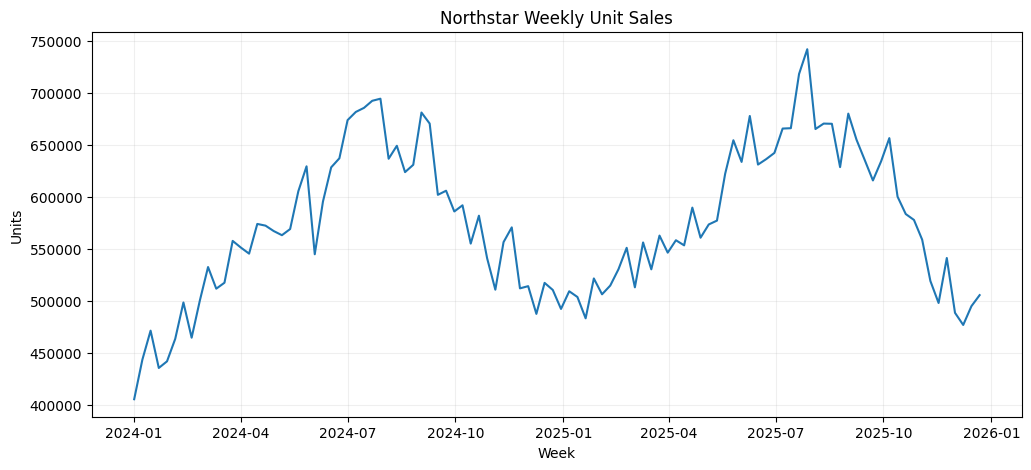

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(weekly['week'], weekly['units'])
plt.title('Northstar Weekly Unit Sales')
plt.xlabel('Week')
plt.ylabel('Units')
plt.grid(alpha=0.2)
plt.show()

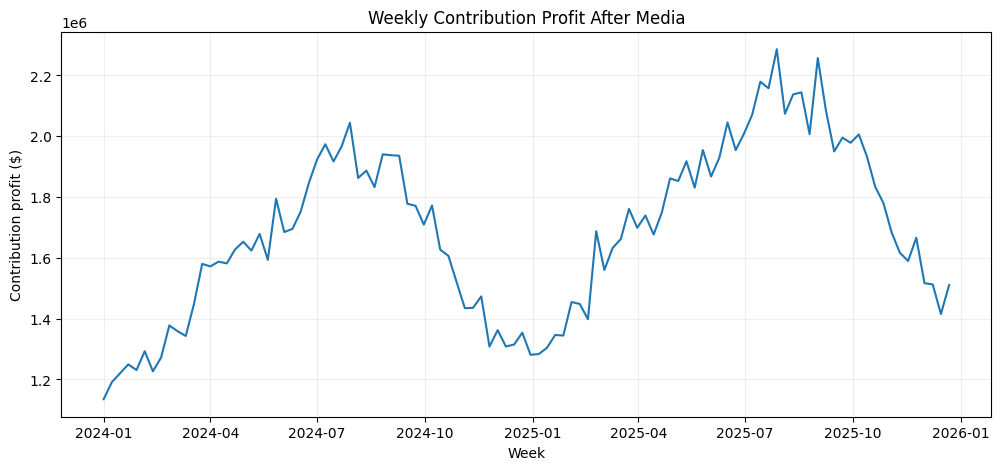

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(weekly['week'], weekly['contribution_profit'])
plt.title('Weekly Contribution Profit After Media')
plt.xlabel('Week')
plt.ylabel('Contribution profit ($)')
plt.grid(alpha=0.2)
plt.show()

Questions to keep in mind:
- Is there visible seasonality?
- Is the business growing?
- Do high-volume weeks also generate high profit?
- Are there weeks where volume rises but profitability weakens?

## 6. Pricing architecture

In [ ]:
price_summary = df[
    ['base_price', 'actual_price', 'competitor_price', 'relative_price_index', 'promo_depth']
].describe().T

price_summary

,count,mean,std,min,25%,50%,75%,max
base_price,2080.0,10.157259,0.209973,9.812025,9.956470,10.152116,10.306470,10.598176
actual_price,2080.0,9.952832,0.533294,7.849620,9.896039,10.097266,10.285834,10.598176
competitor_price,2080.0,9.486755,0.226497,8.880047,9.311523,9.475973,9.659590,10.067634
relative_price_index,2080.0,1.049565,0.058735,0.813282,1.034685,1.063945,1.086329,1.150589
promo_depth,2080.0,0.020144,0.048080,0.000000,0.000000,0.000000,0.000000,0.200000


In [ ]:
promo_summary = (
    df.groupby('promo_depth', as_index=False)
      .agg(
          observations=('units', 'size'),
          avg_price=('actual_price', 'mean'),
          avg_units=('units', 'mean'),
          avg_retail_sales=('retail_sales', 'mean'),
          avg_contribution_profit=('contribution_profit_after_media', 'mean'),
      )
)

promo_summary

,promo_depth,observations,avg_price,avg_units,avg_retail_sales,avg_contribution_profit
0,0.0,1734,10.159665,27676.189735,281325.347030,85869.019034
1,0.1,273,9.126593,32307.377289,295064.653557,76800.925383
2,0.2,73,8.129749,40800.506849,331838.584261,73647.148105


### Do not interpret this causally

If 20% promotion weeks have higher units than no-promo weeks, that does **not** prove the promotion caused the entire difference. Promotions may occur in different seasons, markets, or alongside retailer media.

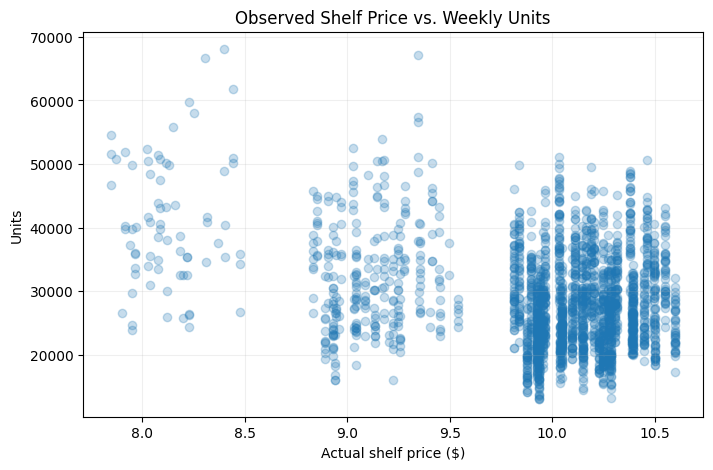

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df['actual_price'], df['units'], alpha=0.25)
plt.title('Observed Shelf Price vs. Weekly Units')
plt.xlabel('Actual shelf price ($)')
plt.ylabel('Units')
plt.grid(alpha=0.2)
plt.show()

The price-volume scatter should look messy. Raw relationships mix market size, distribution, promotions, seasonality, competition, media, and business decisions about when to discount.

## 7. Relative price vs. competitor

In [ ]:
df['price_position'] = pd.cut(
    df['relative_price_index'],
    bins=[-np.inf, 0.97, 1.03, np.inf],
    labels=['Northstar cheaper', 'Near parity', 'Northstar premium']
)

relative_price_summary = (
    df.groupby('price_position', observed=False, as_index=False)
      .agg(
          observations=('units', 'size'),
          avg_relative_price_index=('relative_price_index', 'mean'),
          avg_units=('units', 'mean'),
          avg_contribution_profit=('contribution_profit_after_media', 'mean'),
      )
)

relative_price_summary

,price_position,observations,avg_relative_price_index,avg_units,avg_contribution_profit
0,Northstar cheaper,239,0.919006,35150.656904,75763.199886
1,Near parity,240,1.005288,30829.070833,84384.615716
2,Northstar premium,1601,1.075692,27475.877577,85496.602687


A useful pricing metric is:

**Relative Price Index = Northstar Price / Competitor Price**

- below 1.0 → Northstar is cheaper
- near 1.0 → near parity
- above 1.0 → Northstar carries a premium

## 8. Distribution

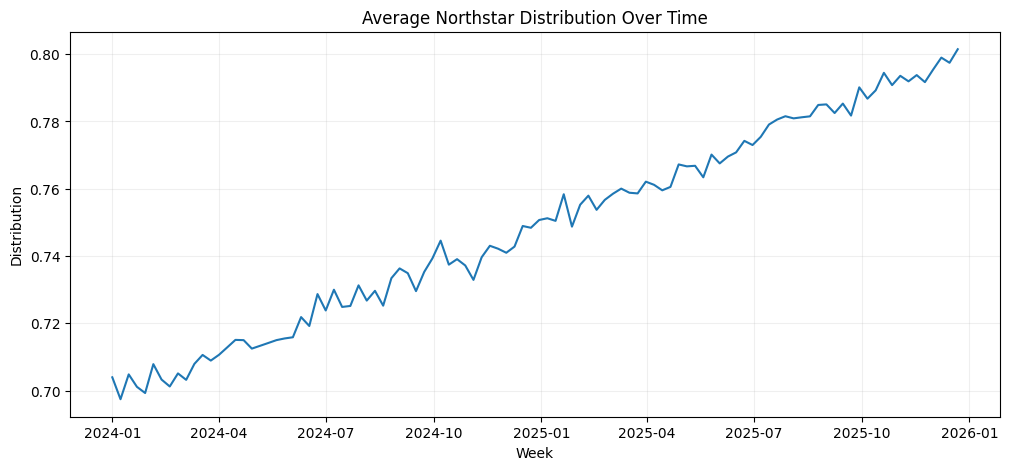

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(weekly['week'], weekly['avg_distribution'])
plt.title('Average Northstar Distribution Over Time')
plt.xlabel('Week')
plt.ylabel('Distribution')
plt.grid(alpha=0.2)
plt.show()

Distribution here translates to the availability of Northstar product in different stores.

Based on the plot, we can say that Northstart is expanding its retail footprint over the two-year period. Some of those additional units may simply be due to more people finding the product and this is where MMM will help us seperate effects of:
- Media
- Distribution expansion
- Price
- Promotions
- Seasonality

In [ ]:
market_distribution = (
    df.groupby('market', as_index=False)
      .agg(
          avg_distribution=('distribution', 'mean'),
          avg_units=('units', 'mean'),
      )
      .sort_values('avg_distribution', ascending=False)
)

market_distribution.head(10)

,market,avg_distribution,avg_units
1,Boston,0.832281,28540.701923
4,Dallas,0.828988,23526.855769
5,Denver,0.823775,35985.394231
12,New York,0.820227,33735.548077
15,Phoenix,0.816725,23204.259615
14,Philadelphia,0.799584,28030.230769
2,Charlotte,0.796254,41575.701923
8,Los Angeles,0.794688,21641.105769
13,Orlando,0.791870,34909.163462
17,San Francisco,0.765764,19438.250000


Distribution is a critical CPG control. If product availability expands while sales and media also rise, a naive model may give media credit for growth that was actually unlocked by distribution.

## 9. Media investment

In [ ]:
media_cols = [
    'ctv_spend',
    'social_spend',
    'retail_media_spend',
    'search_spend',
]

media_summary = df[media_cols].agg(['mean', 'median', 'std', 'min', 'max']).T
media_summary

,mean,median,std,min,max
ctv_spend,6017.395251,4032.419596,7259.867202,0.000000,51677.036741
social_spend,5225.275589,4650.793389,2968.601617,486.635397,20380.628478
retail_media_spend,4160.411557,3459.245971,2965.472723,151.544692,26105.837069
search_spend,2046.245550,1789.399808,1268.425494,56.498276,9895.859143


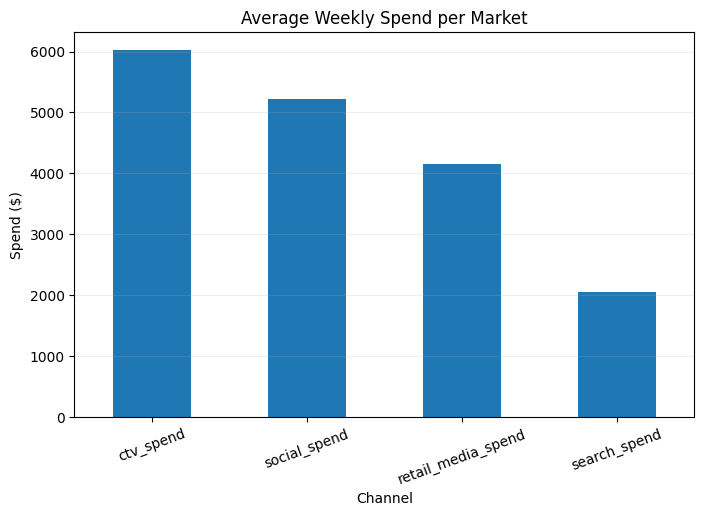

In [ ]:
avg_channel_spend = df[media_cols].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
avg_channel_spend.plot(kind='bar')
plt.title('Average Weekly Spend per Market')
plt.xlabel('Channel')
plt.ylabel('Spend ($)')
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.2)
plt.show()

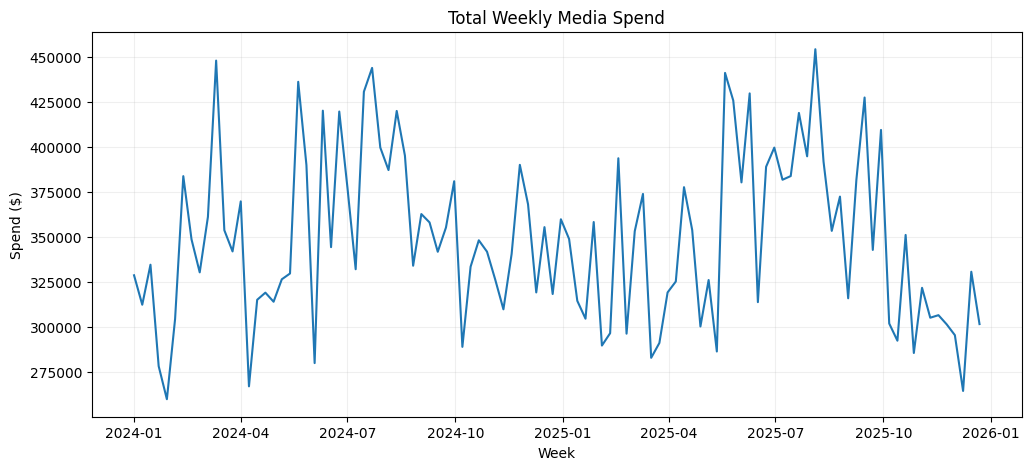

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(weekly['week'], weekly['media_spend'])
plt.title('Total Weekly Media Spend')
plt.xlabel('Week')
plt.ylabel('Spend ($)')
plt.grid(alpha=0.2)
plt.show()

## 10. Media and promotions move together

In [ ]:
promo_media = (
    df.groupby('promo_flag', as_index=False)
      .agg(
          ctv_spend=('ctv_spend', 'mean'),
          social_spend=('social_spend', 'mean'),
          retail_media_spend=('retail_media_spend', 'mean'),
          search_spend=('search_spend', 'mean'),
          units=('units', 'mean'),
      )
)

promo_media

,promo_flag,ctv_spend,social_spend,retail_media_spend,search_spend,units
0,0,6052.876102,5260.670317,3589.077155,2057.055216,27676.189735
1,1,5839.580816,5047.892763,7023.688589,1992.072253,34099.280347


If retail media is systematically higher during promotion weeks, promotion and retail media are **correlated business actions**.

That creates an attribution problem: was the sales lift caused by the discount, retailer media, or both?

## 11. Correlation matrix

In [ ]:
corr_cols = [
    'units', 'actual_price', 'promo_depth', 'competitor_price',
    'relative_price_index', 'distribution', 'ctv_spend',
    'social_spend', 'retail_media_spend', 'search_spend'
]

corr = df[corr_cols].corr()
corr.round(2)

,units,actual_price,promo_depth,competitor_price,relative_price_index,distribution,ctv_spend,social_spend,retail_media_spend,search_spend
units,1.00,-0.28,0.35,0.15,-0.33,0.13,0.19,0.28,0.35,0.23
actual_price,-0.28,1.00,-0.92,0.12,0.91,0.08,0.00,0.02,-0.37,0.04
promo_depth,0.35,-0.92,1.00,-0.00,-0.88,0.00,-0.01,-0.04,0.41,-0.03
competitor_price,0.15,0.12,-0.00,1.00,-0.31,0.40,-0.03,-0.04,-0.04,-0.06
relative_price_index,-0.33,0.91,-0.88,-0.31,1.00,-0.10,0.02,0.04,-0.34,0.06
distribution,0.13,0.08,0.00,0.40,-0.10,1.00,-0.05,-0.11,-0.10,-0.13
ctv_spend,0.19,0.00,-0.01,-0.03,0.02,-0.05,1.00,0.08,0.01,0.05
social_spend,0.28,0.02,-0.04,-0.04,0.04,-0.11,0.08,1.00,0.12,0.13
retail_media_spend,0.35,-0.37,0.41,-0.04,-0.34,-0.10,0.01,0.12,1.00,0.09
search_spend,0.23,0.04,-0.03,-0.06,0.06,-0.13,0.05,0.13,0.09,1.00


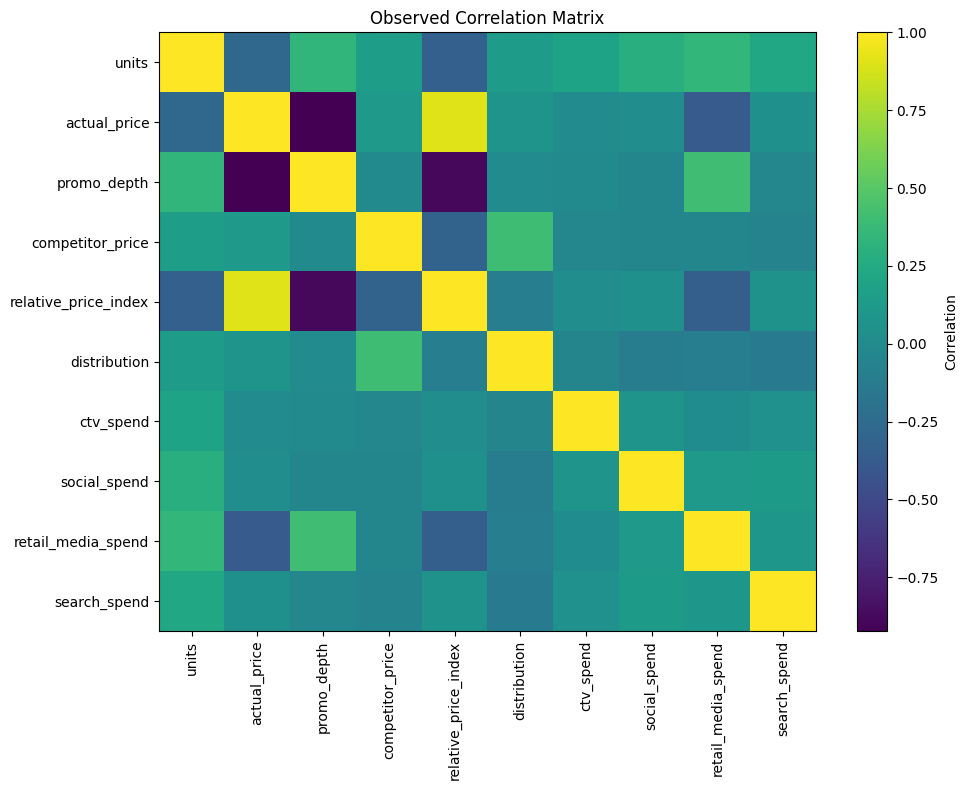

In [ ]:
plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title('Observed Correlation Matrix')
plt.tight_layout()
plt.show()

Correlation is useful diagnostically, but it is not attribution. Media may rise when demand is expected to be strong; promotions may happen when sales are expected to be weak; distribution may trend upward; and multiple levers can move together.

## 12. Market heterogeneity

In [ ]:
market_summary = (
    df.groupby('market', as_index=False)
      .agg(
          avg_units=('units', 'mean'),
          avg_price=('actual_price', 'mean'),
          promo_rate=('promo_flag', 'mean'),
          avg_distribution=('distribution', 'mean'),
          avg_media_spend=('total_media_spend', 'mean'),
          avg_contribution_profit=('contribution_profit_after_media', 'mean'),
      )
      .sort_values('avg_units', ascending=False)
)

market_summary

,market,avg_units,avg_price,promo_rate,avg_distribution,avg_media_spend,avg_contribution_profit
2,Charlotte,41575.701923,10.012273,0.144231,0.796254,22597.408034,126348.142819
5,Denver,35985.394231,10.032581,0.163462,0.823775,17481.078374,112079.782402
13,Orlando,34909.163462,9.833455,0.134615,0.791870,18331.386343,102297.099057
12,New York,33735.548077,9.740413,0.182692,0.820227,19172.175297,94892.840877
0,Atlanta,33509.451923,10.111523,0.192308,0.733441,21640.315980,100361.205302
11,Nashville,32795.336538,9.956313,0.134615,0.629325,22016.741893,94161.834895
6,Detroit,31884.230769,9.861640,0.153846,0.722597,23999.473729,86995.397905
3,Chicago,31559.663462,10.086499,0.163462,0.708259,16123.709428,98244.056113
1,Boston,28540.701923,9.902433,0.153846,0.832281,15974.924632,83699.874957
14,Philadelphia,28030.230769,9.939834,0.211538,0.799584,15830.965237,82787.710551


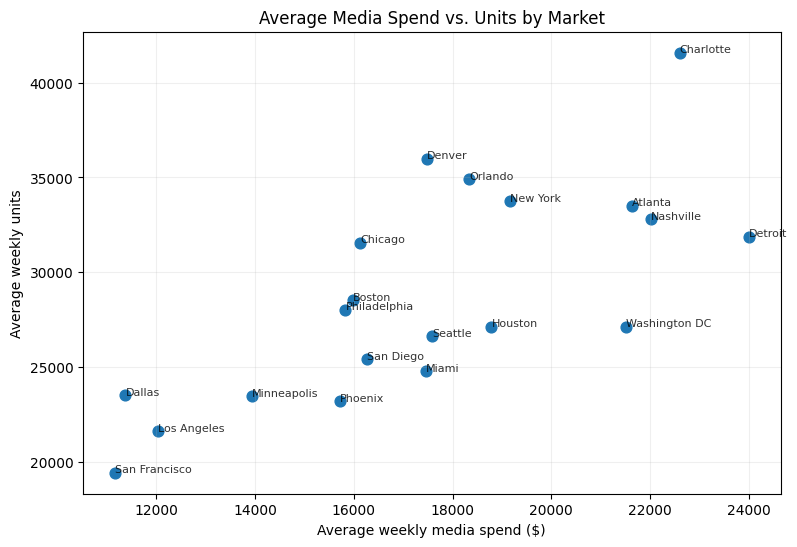

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(
    market_summary['avg_media_spend'],
    market_summary['avg_units'],
    s=60,
)

for _, row in market_summary.iterrows():
    plt.annotate(
        row['market'],
        (row['avg_media_spend'], row['avg_units']),
        fontsize=8,
        alpha=0.8,
    )

plt.title('Average Media Spend vs. Units by Market')
plt.xlabel('Average weekly media spend ($)')
plt.ylabel('Average weekly units')
plt.grid(alpha=0.2)
plt.show()

A higher-spend market may also be larger, better distributed, stronger for the brand, or exposed to different price and competitive conditions. Cross-market spend-sales correlation is not ROAS.

## 13. Profitability by promotional depth

In [ ]:
profit_by_promo = (
    df.groupby('promo_depth', as_index=False)
      .agg(
          avg_units=('units', 'mean'),
          avg_retail_sales=('retail_sales', 'mean'),
          avg_manufacturer_revenue=('manufacturer_net_revenue', 'mean'),
          avg_gross_profit=('gross_profit_before_media', 'mean'),
          avg_contribution_profit=('contribution_profit_after_media', 'mean'),
      )
)

profit_by_promo

,promo_depth,avg_units,avg_retail_sales,avg_manufacturer_revenue,avg_gross_profit,avg_contribution_profit
0,0.0,27676.189735,281325.347030,196927.742921,102828.697823,85869.019034
1,0.1,32307.377289,295064.653557,206545.257490,96700.174706,76800.925383
2,0.2,40800.506849,331838.584261,232287.008983,93565.285695,73647.148105


This is central to the later pricing story. A deeper promotion can increase volume while reducing margin per unit. The best volume strategy is not automatically the best profit strategy.

## 14. Simple year-over-year comparison

In [ ]:
year_summary = (
    df.groupby('year', as_index=False)
      .agg(
          units=('units', 'sum'),
          retail_sales=('retail_sales', 'sum'),
          manufacturer_revenue=('manufacturer_net_revenue', 'sum'),
          media_spend=('total_media_spend', 'sum'),
          contribution_profit=('contribution_profit_after_media', 'sum'),
          avg_price=('actual_price', 'mean'),
          avg_distribution=('distribution', 'mean'),
      )
)

year_summary

,year,units,retail_sales,manufacturer_revenue,media_spend,contribution_profit,avg_price,avg_distribution
0,2024,29892479,2.916596e+08,2.041617e+08,1.863620e+07,8.389108e+07,9.802116,0.723342
1,2025,29896385,3.009354e+08,2.106548e+08,1.765840e+07,9.134869e+07,10.109458,0.774441


If Year 2 has higher units and higher media spend, that alone does not mean media caused the growth. Price, distribution, competition, seasonality, and market dynamics also changed.

## 15. What should the baseline MMM explain?

The baseline model should attempt to separate:

### Media
- Connected TV
- Paid Social
- Retail Media
- Paid Search

### Commercial controls
- actual price
- promotions
- competitor price / relative price position
- distribution
- seasonality
- market differences

### Key measurement risks
1. Media is not randomly assigned.
2. Promotions and retail media often occur together.
3. Distribution trends upward.
4. Markets differ structurally.
5. Price is a business decision, not a random treatment.

The baseline MMM will therefore be **observational**. Later, incrementality tests will provide an external causal benchmark.

## 16. Save useful EDA summary tables

In [ ]:
market_summary_path = OUTPUT_DIR / 'eda_market_summary.csv'
promo_summary_path = OUTPUT_DIR / 'eda_promo_summary.csv'
year_summary_path = OUTPUT_DIR / 'eda_year_summary.csv'

market_summary.to_csv(market_summary_path, index=False)
promo_summary.to_csv(promo_summary_path, index=False)
year_summary.to_csv(year_summary_path, index=False)

print('Saved:')
print(market_summary_path)
print(promo_summary_path)
print(year_summary_path)

Saved:
/content/drive/MyDrive/northstar_cpg/outputs/eda_market_summary.csv
/content/drive/MyDrive/northstar_cpg/outputs/eda_promo_summary.csv
/content/drive/MyDrive/northstar_cpg/outputs/eda_year_summary.csv


# Notebook 02 conclusion

We now understand the observed Northstar business environment without looking at the hidden truth.

The main analytical challenge is:

> **Price, promotions, media, distribution, and demand conditions move together.**

Historical correlation alone cannot tell us which lever truly caused incremental sales.

## Next: Notebook 03 — Baseline MMM

Notebook 03 will fit the first observational MMM and estimate channel contribution, adstock, saturation, response curves, efficiency, and uncertainty. Notebook 04 will then introduce incrementality evidence and test whether the observational MMM agrees with it.